# Assignment 3

## MCMC and 2D Ising Model

In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

In [4]:
J = 1.0
KB = 1.0
N = 20
SEED = 200101723

### Problem A

In [5]:
@njit
def flip_energy(spins, i, j):
    n = spins.shape[0]
    neighbors = (
        spins[(i - 1) % n, j] +
        spins[(i + 1) % n, j] +
        spins[i, (j - 1) % n] +
        spins[i, (j + 1) % n]
    )
    return 2 * J * spins[i, j] * neighbors

@njit
def metropolis_step(spins, temperature, rng):
    i, j = rng.integers(0, spins.shape[0], size=2)
    delta_energy = flip_energy(spins, i, j)

    if delta_energy <= 0 or rng.random() < np.exp(-delta_energy / (KB * temperature)):
        spins[i, j] *= -1
        return 1

    return 0

@njit
def advance_ising(spins, temperature, sweeps, rng):
    n = spins.shape[0]
    magnetization = np.empty(sweeps + 1)
    magnetization[0] = spins.mean()
    accepted = 0

    for sweep in range(1, sweeps + 1):
        for _ in range(n * n):
            accepted += metropolis_step(spins, temperature, rng)

        magnetization[sweep] = spins.mean()

    return magnetization, accepted

def run_ising(temperature, n, sweeps, seed, initial="up"):
    rng = np.random.default_rng(seed)

    if initial == "up":
        spins = np.ones((n, n), dtype=int)
    elif initial == "random":
        spins = rng.choice(np.array([-1, 1]), size=(n, n))
    else:
        raise ValueError("Initial configuration must be 'up' or 'random'")

    magnetization, accepted = advance_ising(spins, temperature, sweeps, rng)

    return spins, magnetization, accepted / (sweeps * n * n)

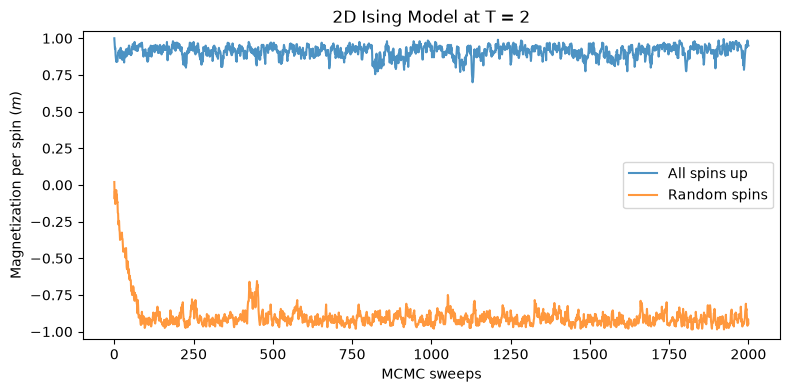

In [6]:
T = 2.0
SWEEPS = 2000

_, m_up, _ = run_ising(T, N, SWEEPS, SEED, initial="up")
_, m_random, _ = run_ising(T, N, SWEEPS, SEED + 1, initial="random")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(m_up, label="All spins up", alpha=0.8)
ax.plot(m_random, label="Random spins", alpha=0.8)

ax.set(
    xlabel="MCMC sweeps",
    ylabel="Magnetization per spin $(m)$",
    title="2D Ising Model at T = 2",
    ylim=(-1.05, 1.05)
)
ax.legend()
plt.show()

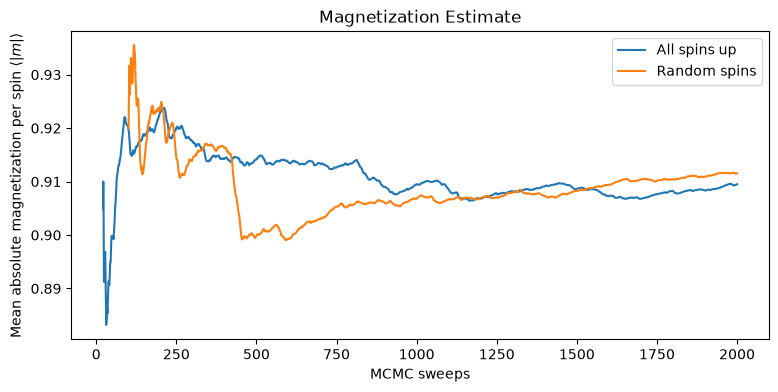

In [7]:
BURNIN_UP = 20
BURNIN_RANDOM = 100

def running_average(m_values, burnin):
    samples = np.abs(m_values[burnin + 1:])
    return np.cumsum(samples) / np.arange(1, len(samples) + 1)

avg_up = running_average(m_up, BURNIN_UP)
avg_random = running_average(m_random, BURNIN_RANDOM)

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(np.arange(BURNIN_UP + 1, SWEEPS + 1), avg_up,
        label="All spins up")
ax.plot(np.arange(BURNIN_RANDOM + 1, SWEEPS + 1), avg_random,
        label="Random spins")

ax.set(
    xlabel="MCMC sweeps",
    ylabel=r"Mean absolute magnetization per spin $\langle|m|\rangle$",
    title="Magnetization Estimate"
)
ax.legend()
plt.show()

### Problem B

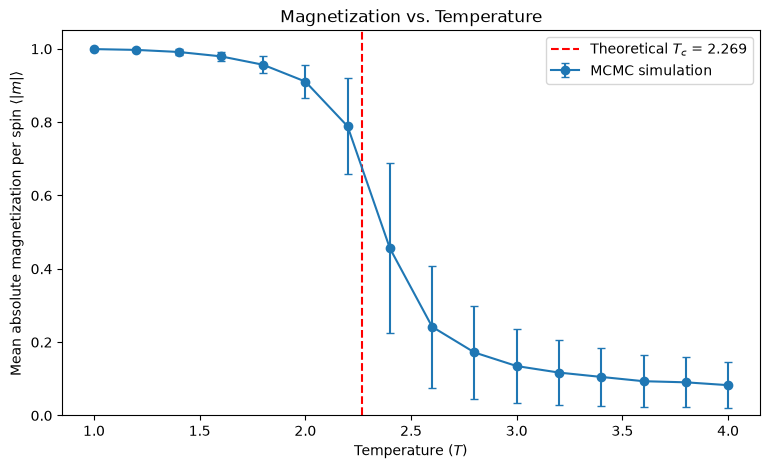

In [19]:
TEMPERATURES = np.round(np.arange(1.0, 4.01, 0.2), 1)

SWEEPS_B = 5000
BURNIN_B = 200
CHAINS = 5

mean_m = []
std_m = []

for t_index, temperature in enumerate(TEMPERATURES):
    samples = []

    for chain in range(CHAINS):
        seed = SEED + t_index * CHAINS + chain

        _, magnetization, _ = run_ising(
            temperature, N, SWEEPS_B, seed, initial="up"
        )

        samples.extend(np.abs(magnetization[BURNIN_B + 1:]))

    mean_m.append(np.mean(samples))
    std_m.append(np.std(samples, ddof=1))

mean_m = np.array(mean_m)
std_m = np.array(std_m)

TC = 2 / np.log(1 + np.sqrt(2))

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    TEMPERATURES, mean_m, yerr=std_m,
    fmt="o-", capsize=3, label="MCMC simulation"
)

ax.axvline(
    TC, color="red", linestyle="--",
    label=f"Theoretical $T_c$ = {TC:.3f}"
)

ax.set(
    xlabel="Temperature $(T)$",
    ylabel=r"Mean absolute magnetization per spin $\langle|m|\rangle$",
    title="Magnetization vs. Temperature",
    ylim=(0, 1.05)
)

ax.legend()
plt.show()

## Path-Integral Monte Carlo at Finite Temperature

In [11]:
BETA = 1.0
DELTA_TAU = 0.1
N_TAU = int(round(BETA / DELTA_TAU))

M = 1.0
OMEGA = 1.0
HBAR = 1.0

SWEEPS_2 = 50_000

# Initialize a cold path
x_path = np.zeros(N_TAU)

print("Number of time slices:", N_TAU)
print("Initial path:", x_path)

Number of time slices: 10
Initial path: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


### Problem A

In [12]:
def action(x_left, x_right):
    kinetic = (x_right - x_left)**2 / (2 * DELTA_TAU)
    potential = DELTA_TAU * x_left**2 / 2
    return kinetic + potential

def delta_action(x_path, x_prime, i):
    x_left = x_path[i - 1]
    x_right = x_path[(i + 1) % N_TAU]

    return (
        action(x_left, x_prime)
        + action(x_prime, x_right)
        - action(x_left, x_path[i])
        - action(x_path[i], x_right)
    )

def metropolis_sweep(x_path, hitsize, rng):
    accepted = 0

    for _ in range(N_TAU):
        i = rng.integers(N_TAU)
        x_prime = x_path[i] + rng.uniform(-hitsize, hitsize)
        dS = delta_action(x_path, x_prime, i)

        if dS <= 0 or rng.random() < np.exp(-dS):
            x_path[i] = x_prime
            accepted += 1

    return accepted

def run_pimc(sweeps, hitsize, seed):
    rng = np.random.default_rng(seed)
    x_path = np.zeros(N_TAU)

    x2_values = np.empty(sweeps)
    accepted = 0

    for sweep in range(sweeps):
        accepted += metropolis_sweep(x_path, hitsize, rng)
        x2_values[sweep] = np.mean(x_path**2)

    acceptance = accepted / (sweeps * N_TAU)

    return x2_values, acceptance

hitsizes = np.arange(0.05, 2.1, 0.05)
for h in hitsizes:
    _, acceptance = run_pimc(5000, h, SEED)
    print(f"h = {h:.2f}, acceptance = {acceptance:.3f}")

h = 0.05, acceptance = 0.953
h = 0.10, acceptance = 0.911
h = 0.15, acceptance = 0.866
h = 0.20, acceptance = 0.822
h = 0.25, acceptance = 0.778
h = 0.30, acceptance = 0.735
h = 0.35, acceptance = 0.699
h = 0.40, acceptance = 0.664
h = 0.45, acceptance = 0.623
h = 0.50, acceptance = 0.592
h = 0.55, acceptance = 0.562
h = 0.60, acceptance = 0.530
h = 0.65, acceptance = 0.505
h = 0.70, acceptance = 0.476
h = 0.75, acceptance = 0.447
h = 0.80, acceptance = 0.427
h = 0.85, acceptance = 0.408
h = 0.90, acceptance = 0.384
h = 0.95, acceptance = 0.367
h = 1.00, acceptance = 0.353
h = 1.05, acceptance = 0.334
h = 1.10, acceptance = 0.318
h = 1.15, acceptance = 0.306
h = 1.20, acceptance = 0.294
h = 1.25, acceptance = 0.280
h = 1.30, acceptance = 0.270
h = 1.35, acceptance = 0.263
h = 1.40, acceptance = 0.254
h = 1.45, acceptance = 0.245
h = 1.50, acceptance = 0.237
h = 1.55, acceptance = 0.229
h = 1.60, acceptance = 0.222
h = 1.65, acceptance = 0.214
h = 1.70, acceptance = 0.207
h = 1.75, acce

Acceptance rate: 0.502


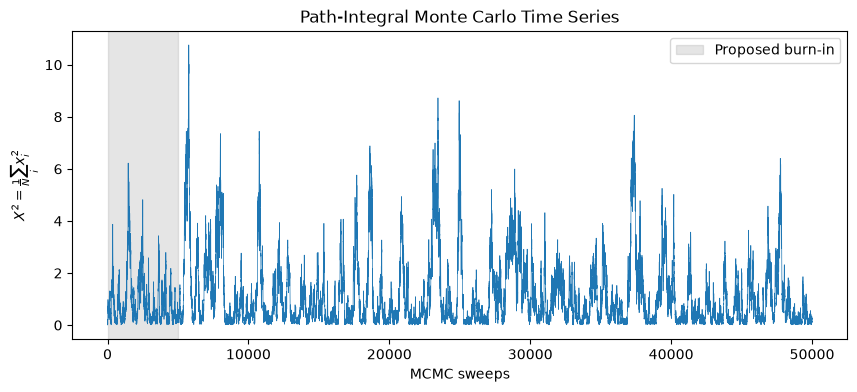

In [13]:
HITSIZE = 0.65

BURNIN_2 = 5000

x2_values, acceptance = run_pimc(
    SWEEPS_2, HITSIZE, SEED
)

print(f"Acceptance rate: {acceptance:.3f}")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(np.arange(1, SWEEPS_2 + 1), x2_values, linewidth=0.5)
ax.axvspan(0, BURNIN_2, color="gray", alpha=0.2, label="Proposed burn-in")

ax.set(
    xlabel="MCMC sweeps",
    ylabel=r"$X^2 = \frac{1}{N}\sum_i x_i^2$",
    title="Path-Integral Monte Carlo Time Series"
)
ax.legend()
plt.show()

Estimated <x²>: 1.14627
Retained sweeps: 45000
Exact continuum result: 1.08198


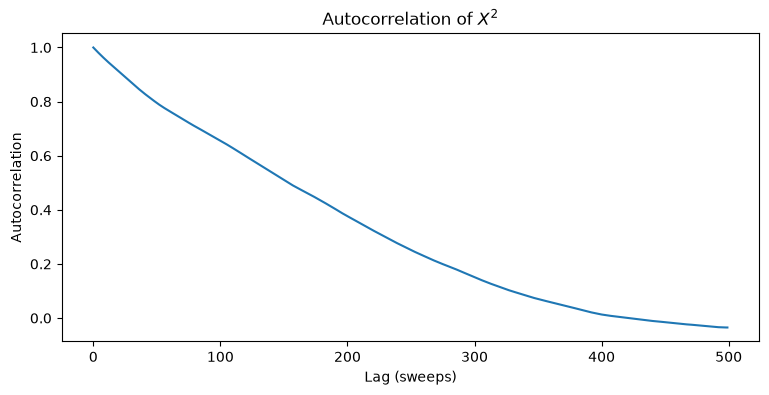

In [14]:
samples = x2_values[BURNIN_2:]

x2_mean = np.mean(samples)

print(f"Estimated <x²>: {x2_mean:.5f}")
print(f"Retained sweeps: {len(samples)}")

x2_exact = 0.5 / np.tanh(BETA / 2)

print(f"Exact continuum result: {x2_exact:.5f}")

def autocorrelation(data):
    centered = data - np.mean(data)
    n = len(centered)

    fft = np.fft.rfft(centered, n=2*n)
    acf = np.fft.irfft(fft * np.conj(fft))[:n]

    acf /= np.arange(n, 0, -1)
    acf /= acf[0]

    return acf

acf = autocorrelation(samples)

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(np.arange(500), acf[:500])

ax.set(
    xlabel="Lag (sweeps)",
    ylabel="Autocorrelation",
    title="Autocorrelation of $X^2$"
)
plt.show()

Naive standard error: 0.006340


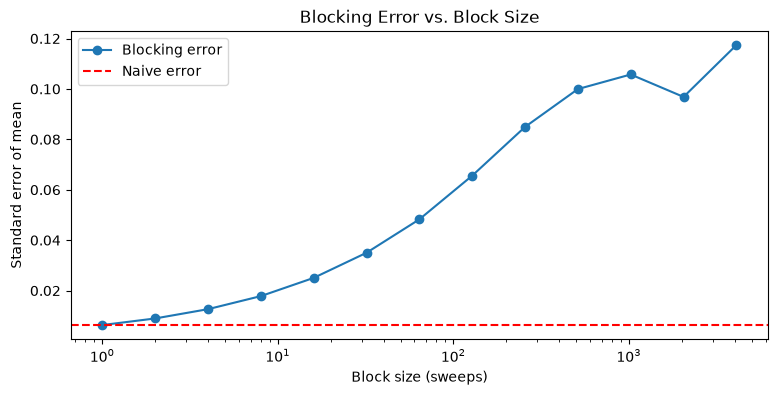

In [15]:
naive_error = np.std(samples, ddof=1) / np.sqrt(len(samples))
print(f"Naive standard error: {naive_error:.6f}")

def blocking_error(data, block_size):
    n_blocks = len(data) // block_size

    if n_blocks < 2:
        raise ValueError("Need at least two blocks")

    trimmed = data[:n_blocks * block_size]
    blocks = trimmed.reshape(n_blocks, block_size)

    block_means = np.mean(blocks, axis=1)

    return np.std(block_means, ddof=1) / np.sqrt(n_blocks)

block_sizes = []
block_errors = []

for size in [2**k for k in range(13)]:
    n_blocks = len(samples) // size

    if n_blocks < 10:
        break

    block_sizes.append(size)
    block_errors.append(blocking_error(samples, size))

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(block_sizes, block_errors, "o-", label="Blocking error")
ax.axhline(
    naive_error, color="red", linestyle="--",
    label="Naive error"
)

ax.set(
    xlabel="Block size (sweeps)",
    ylabel="Standard error of mean",
    title="Blocking Error vs. Block Size",
    xscale="log"
)

ax.legend()
plt.show()

In [16]:
nonpositive = np.where(acf[1:] <= 0)[0]

cutoff = int(nonpositive[0] + 1) if len(nonpositive) else len(acf)

tau_int = 0.5 + np.sum(acf[1:cutoff])

print(f"Integrated autocorrelation time: {tau_int:.2f} sweeps")
print(f"ACF cutoff: {cutoff} sweeps")
print(f"Effective sample size: {len(samples)/(2*tau_int):.1f}")

Integrated autocorrelation time: 165.34 sweeps
ACF cutoff: 421 sweeps
Effective sample size: 136.1
